# Sea Surface Temperature Reconstruction under cloud occlusion

Sea Surface Temperature (SST) data are mostly acquired by means of satellites detecting the infrared radiation emitted from the sea surface. This radiation can be absorbed by clouds, causing large occlusions in collected observations. Filling these gaps is the task of your exam.

We focus on a region of the north adriatic sea. Data are taken from the MODIS dataset; we use the nigthly data collected by the Aqua satellite.


In [2]:
import numpy as np
import pandas as pd

import tensorflow as tf
from tensorflow import keras

import matplotlib.pyplot as plt

In [3]:
seed = 38
tf.random.set_seed(seed)
np.random.seed(seed)

In [ ]:
#data
!gdown 1cxZCt2CzMo9AolJ9k-je3b4w9t0Ibpvc
!gdown 1L3PxazNUnc_cw9XvHfj_J-fhhBXv41YY
!gdown 1tR7U8ndBktwiAhmpyQZG2nv5kRcX0mtd
#dates
!gdown 1ROGlbqknu47uyZs89J1oBml6vwE-wtfx
!gdown 1wpKfWxwf9XXJixdUrrjN-idcAZ5H3-0C
!gdown 1hGg-J7ipuil1Hp46YTIVWzXkSHc2avBE

In [ ]:
#land-sea mask
!gdown 1F0GGmrrGtSHizdf0COyHErNqMf9FazCK

In [ ]:
#a statistical baseline
!gdown 1JfVhw5HHlUOj_3UxVFT-kTaOVs6ZRUEJ

just to make a copy of the data

In [ ]:
import shutil
from google.colab import drive

drive.mount('/content/drive')

destination_folder = '/content/drive/MyDrive/DeepProject/'
shutil.move('dates_test_night.npy', destination_folder + 'dates_test_night.npy')
shutil.move('dates_train_night.npy', destination_folder + 'dates_train_night.npy')
shutil.move('dates_val_night.npy', destination_folder + 'dates_val_night.npy')
shutil.move('land_sea_mask.npy', destination_folder + 'land_sea_mask.npy')
shutil.move('stat_baseline.npy', destination_folder + 'stat_baseline.npy')
shutil.move('x_test_night.npy', destination_folder + 'x_test_night.npy')
shutil.move('x_train_night.npy', destination_folder + 'x_train_night.npy')
shutil.move('x_val_night.npy', destination_folder + 'x_val_night.npy')


In [4]:
x_train_n = np.load(destination_folder + 'x_train_night.npy')
x_val_n = np.load(destination_folder + 'x_val_night.npy')
x_test_n = np.load(destination_folder + 'x_test_night.npy')
dates_train_n = np.load(destination_folder + 'dates_train_night.npy')
dates_val_n = np.load(destination_folder + 'dates_val_night.npy')
dates_test_n = np.load(destination_folder + 'dates_test_night.npy')
land_sea_mask = np.load(destination_folder + 'land_sea_mask.npy')
baseline = np.load(destination_folder + 'stat_baseline.npy')


total_sea = np.sum(land_sea_mask)

## Le us inspect and visualize data.

In [5]:
print(x_train_n.shape)
print(x_val_n.shape)
print(x_test_n.shape)

print(f"min train temperature: {np.nanmin(x_train_n)}")
print(f"max train temperature: {np.nanmax(x_train_n)}")
print(f"mean train temperature: {np.nanmean(x_train_n)}")
print(f"std train temperature: {np.nanstd(x_train_n)}\n")

print(f"min val temperature: {np.nanmin(x_val_n)}")
print(f"max val temperature: {np.nanmax(x_val_n)}\n")

print(f"min test temperature: {np.nanmin(x_test_n)}")
print(f"max test temperature: {np.nanmax(x_test_n)}")


(5832, 128, 128)
(1090, 128, 128)
(895, 128, 128)
min train temperature: 0.08999999612569809
max train temperature: 30.654998779296875
mean train temperature: 19.480466842651367
std train temperature: 5.093418598175049

min val temperature: 1.274999976158142
max val temperature: 29.979999542236328

min test temperature: 2.884999990463257
max test temperature: 30.594999313354492


Let us visualize a few images. Occluded area are coded with nans: they may correspond to land or clouds. nans are rendered in blank. 

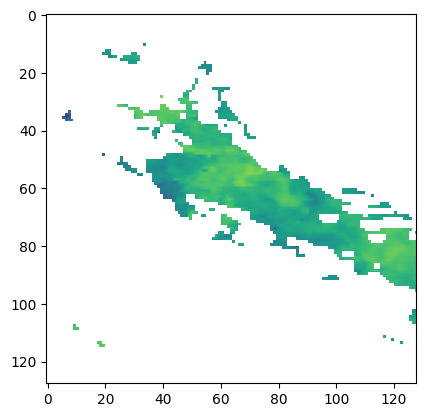

In [9]:
i = np.random.randint(0, x_train_n.shape[0])
plt.imshow(x_train_n[i]); #nans are blank; they could be land or clouds

In [10]:
print(dates_train_n.shape) # from 2002-07-04 to 2018-07-04
print(dates_val_n.shape)   # from 2018-07-04 to 2021-07-04
print(dates_test_n.shape)  # from 2021-07-04 to 2023-12-31

(5832,)
(1090,)
(895,)


We know the part of the territory corresponding to land.
In the land-sea mask, 1 is for sea, and 0 for land.

(128, 128)
sea percentage =  0.408203125


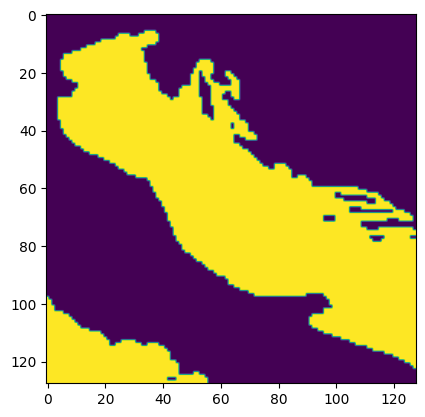

In [13]:
print(land_sea_mask.shape)
plt.imshow(land_sea_mask)
total_sea = np.sum(land_sea_mask)
print("sea percentage = ", total_sea/(128*128))

You can also make use of a statistical baseline, which already provides an interesting approximation. Your task is to make meaningful improvements to it.

In [14]:
print(baseline.shape) # 365 days | 128x128 image
print(f"min baseline temperature: {np.nanmin(baseline)}")
print(f"max baseline temperature: {np.nanmax(baseline)}")

(366, 128, 128)
min baseline temperature: 0.0
max baseline temperature: 27.10306060332889


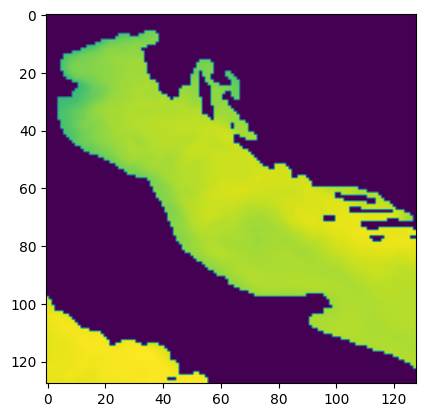

In [15]:
i = np.random.randint(0, baseline.shape[0])
plt.imshow(baseline[i]); #nans are blank; they could be land or clouds

# Normalization

## Gaussian Norm.

Gaussian normalization yielded the best results.

In [6]:
x_train_mean = np.nanmean(x_train_n)
x_train_std = np.nanstd(x_train_n)

In [7]:
x_train_n = (x_train_n - x_train_mean) / x_train_std
x_val_n = (x_val_n - x_train_mean) / x_train_std
x_test_n = (x_test_n - x_train_mean) / x_train_std

baseline_nan = np.where(land_sea_mask,baseline,np.nan)
baseline_nan = (baseline_nan - x_train_mean) / x_train_std
baseline = np.where(land_sea_mask,baseline_nan, 0.0)

# Generator

A problem with occluded data is that we do not have ground truth available, as we do not know the actual sea temperature beneath the clouds.

To address this, we create an artificial ground truth by extending the clouded region. Specifically, we superimpose the clouds from a randomly chosen different day onto a given day, providing a configurable amount of auxiliary clouds.

In [8]:
def generator(batch_size, dataset, dates):
    size = 128
    while True:
        batch_x = np.zeros((batch_size, size, size, 4))
        batch_y = np.zeros((batch_size, size, size, 3))

        for b in range(batch_size):
            # Choose an image with a sufficiently large area of visible sea
            found = False
            while not found:
              i = np.random.randint(0, dataset.shape[0])
              visible = np.sum(~np.isnan(dataset[i])/total_sea)
              if visible > 0.4:
                found = True
            image_current = np.nan_to_num(dataset[i], nan=0)
            mask_current = np.isnan(dataset[i])

            # Extending clouds
            found = False
            while not found:
              r = np.random.randint(0, dataset.shape[0])
              mask_r = np.isnan(dataset[r])
              mask_or_r = np.logical_or(mask_current, mask_r)
              nnans = np.sum(~mask_or_r)/total_sea
              if nnans > 0.05 and nnans < min(visible-.1,0.4):
                found = True

            artificial_mask_current = ~mask_or_r  #1 visible, 0 masked

            # Apply the enlarged mask to the current day's image
            image_masked_current = np.where(artificial_mask_current, image_current, 0)

            # we tune the statistical baseline according to the average sea temperature of the current day

            # convert the current date to a datetime object using pandas
            date_series = pd.to_datetime(dates[i], unit='D', origin='unix')
            day_of_year = date_series.dayofyear

            #avg temp of the current day
            image_masked_nan = np.where(artificial_mask_current, image_current, np.nan)

            avg_temp_real = np.nanmean(image_masked_nan)
            avg_temp_baseline = np.nanmean(np.where(artificial_mask_current, baseline[day_of_year - 1],np.nan))
            tuned_baseline = baseline[day_of_year - 1] + avg_temp_real - avg_temp_baseline  # Adjust the baseline to match the average temperature of the current day
            tuned_baseline = np.where(land_sea_mask,tuned_baseline,.0)

            # Removing nans for usage in neural networks
            mask_current = np.logical_not(mask_current) # 1 for clear sea, 0 for land/clouds
            diff_mask = np.logical_and(~artificial_mask_current,mask_current) # 1 for clear sea, 0 for land/clouds and artificial clouds

            # Create batch_x and batch_y
            batch_x[b, ..., 0] = image_masked_current            #current artificially clouded image
            batch_x[b, ..., 1] = artificial_mask_current         #current artificial mask
            batch_x[b, ..., 2] = land_sea_mask                   #land-sea mask
            batch_x[b, ..., 3] = tuned_baseline                  #tuned baseline

            batch_y[b, ..., 0] = image_current                   #real image
            batch_y[b, ..., 1] = mask_current                    #real mask
            batch_y[b, ..., 2] = diff_mask                       #artificial mask used for the input

        yield batch_x, batch_y

Generators for gaussian normalized data

In [9]:
batch_size = 32

train_gen = generator(batch_size, x_train_n, dates_train_n)
val_gen = generator(batch_size, x_val_n, dates_val_n)
test_gen = generator(batch_size, x_test_n, dates_test_n)

The generator returns two sets of data, called batch_x and batch_y. The idea is that batch_x data are possible inputs for the neural network, while batch_y data provide ground_truth information that can be used for defining the loss function, or auxiliary metrics. Let us inspect them in more detail.

In [10]:
import matplotlib.pyplot as plt

def plot_elements(images, titles):

  num_of_images = len(images)
  rows = 1
  cols = num_of_images
  mini = np.nanmin(np.array(images))
  maxi = np.nanmax(np.array(images))
  print(mini,maxi)

  plt.figure(figsize=(10, 10*num_of_images))
  for i in range(num_of_images):
    print(f"image {i}; {np.min(images[i])}, {np.max(images[i])}")
    plt.subplot(rows, cols, i+1)
    plt.imshow(images[i],vmin=mini,vmax=maxi)
    plt.axis('off')
    plt.title(titles[i])
  plt.show()

0.0 27.32499858345335
image 0; 0.0, 27.32499858345335
image 1; 0.0, 27.22999936779661
image 2; 0.0, 26.457946525530787


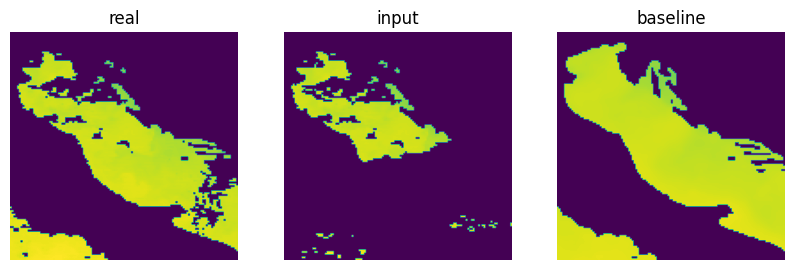

0.0 1.0
image 0; 0.0, 1.0
image 1; 0.0, 1.0
image 2; 0.0, 1.0


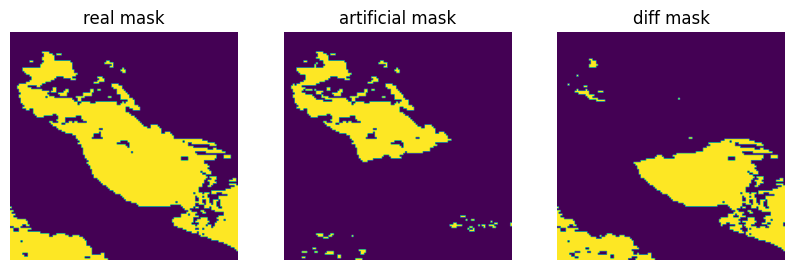

In [15]:
batch_x, batch_y = next(test_gen)
assert(np.sum(np.isnan(batch_x))==0)
assert(np.sum(np.isnan(batch_y))==0)
real_denorm = np.where(batch_y[0,...,1],batch_y[0,...,0]*x_train_std + x_train_mean,0.0)
artificial_denorm = np.where(batch_x[0,...,1],batch_y[0,...,0]*x_train_std + x_train_mean,0.0)
baseline_denorm = np.where(land_sea_mask,batch_x[0,...,3]*x_train_std + x_train_mean,0.0)

plot_elements([real_denorm, artificial_denorm, baseline_denorm], ['real', 'input','baseline'])
plot_elements([batch_y[0,...,1], batch_x[0,...,1], batch_y[0,...,2]],["real mask","artificial mask","diff mask"])

In the first row, we see:
- the real image of the day
- the input passed to the model, that is a masked version of the previous image
- the tentative reconstruction done via the statistical baseline.

All images have been denormalized.

In the second row we see:
- the mask of the current day
- the enlarged masked with additional clouds
- the difference, showing the portion of the image visible in the first one, but occluded in the second. This is the region where the performance of the model must be evaluated


# Remarks

All data in batch_x can be used as input to the model. You may choose to use only a subset of the data or perform additional preprocessing if desired.

Do not modify the test generator, as this could affect the evaluation of the model.

The notebook should include the code for a single model. You may discuss additional experiments by briefly mentioning the results.

The project must be written in tensorflow, as usual.




---



# U-net with 7.8M parameters

In [33]:
from keras.regularizers import l2
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Concatenate, BatchNormalization, Dropout

In [34]:
def down_block(inputs, filters, kernel_size=(3,3), padding='same', activation='relu', dilation_rate=(1, 1), kernel_initializer='he_normal', use_batch_norm=False, dropout_rate=0, weight_decay=1e-3):
    conv = Conv2D(filters, kernel_size, activation=activation, padding=padding, dilation_rate=dilation_rate, kernel_initializer=kernel_initializer, kernel_regularizer=l2(weight_decay))(inputs)
    if use_batch_norm:
        conv = BatchNormalization()(conv)
    if dropout_rate > 0:
        conv = Dropout(dropout_rate)(conv)
    conv = Conv2D(filters, kernel_size, activation=activation, padding=padding, dilation_rate=dilation_rate, kernel_initializer=kernel_initializer, kernel_regularizer=l2(weight_decay))(conv)

    if use_batch_norm:
        conv = BatchNormalization()(conv)
    if dropout_rate > 0:
        conv = Dropout(dropout_rate)(conv)
    pool = MaxPooling2D(pool_size=(2, 2))(conv)
    return conv, pool

def up_block(inputs, skip, filters, kernel_size=(3, 3), padding='same', activation='relu', dilation_rate=(1, 1), kernel_initializer='he_normal', use_batch_norm=False, dropout_rate=0, weight_decay=1e-4):
    up = UpSampling2D(size=(2, 2))(inputs)
    concat = Concatenate()([up, skip])
    conv = Conv2D(filters, kernel_size, activation=activation, padding=padding, dilation_rate=dilation_rate, kernel_initializer=kernel_initializer, kernel_regularizer=l2(weight_decay))(concat)
    if use_batch_norm:
        conv = BatchNormalization()(conv)
    if dropout_rate > 0:
        conv = Dropout(dropout_rate)(conv)
    conv = Conv2D(filters, kernel_size, activation=activation, padding=padding, dilation_rate=dilation_rate, kernel_initializer=kernel_initializer, kernel_regularizer=l2(weight_decay))(conv)
    if use_batch_norm:
        conv = BatchNormalization()(conv)
    if dropout_rate > 0:
        conv = Dropout(dropout_rate)(conv)
    return conv

def unet(img_size=(128, 128), num_channels=4, output_channels=3, dilation_rate=(2, 2), kernel_initializer='he_normal', weight_decay=1e-4):
    inputs = Input(shape=img_size + (num_channels,))
    
    conv1, pool1 = down_block(inputs, 32, kernel_initializer=kernel_initializer, weight_decay=weight_decay)
    conv2, pool2 = down_block(pool1, 64, kernel_initializer=kernel_initializer, weight_decay=weight_decay)
    conv3, pool3 = down_block(pool2, 128, dilation_rate=dilation_rate, kernel_initializer=kernel_initializer, use_batch_norm=True, weight_decay=weight_decay)
    conv4, pool4 = down_block(pool3, 256, dilation_rate=dilation_rate, kernel_initializer=kernel_initializer, use_batch_norm=True, weight_decay=weight_decay)
    
    conv5 = Conv2D(512, (3, 3), activation='relu', padding='same', dilation_rate=(3,3), kernel_initializer=kernel_initializer, kernel_regularizer=l2(weight_decay))(pool4)
    conv5 = Conv2D(512, (3, 3), activation='relu', padding='same', dilation_rate=(3,3), kernel_initializer=kernel_initializer, kernel_regularizer=l2(weight_decay))(conv5)
    conv5 = BatchNormalization()(conv5)
    conv5 = Dropout(0.4)(conv5)
    
    conv6 = up_block(conv5, conv4, 256, dilation_rate=dilation_rate, kernel_initializer=kernel_initializer, use_batch_norm=True, dropout_rate=0.2, weight_decay=weight_decay)
    conv7 = up_block(conv6, conv3, 128, dilation_rate=dilation_rate, kernel_initializer=kernel_initializer, use_batch_norm=True, dropout_rate=0.2, weight_decay=weight_decay)
    conv8 = up_block(conv7, conv2, 64, kernel_initializer=kernel_initializer, weight_decay=weight_decay)
    conv9 = up_block(conv8, conv1, 32, kernel_initializer=kernel_initializer, weight_decay=weight_decay)

    outputs = Conv2D(output_channels, (1, 1), activation='linear', padding="same", kernel_initializer=kernel_initializer)(conv9)

    model = Model(inputs=inputs, outputs=outputs, name="Unet")
    return model

model = unet(img_size=(128, 128), num_channels=4, output_channels=3, kernel_initializer='he_normal')

I experimented with various activation functions, including Swish, Leaky ReLU, and SiLU, but found that ReLU consistently delivered the best performance. The network also benefited significantly from the use of He normal weight initialization, which improved convergence, especially in deeper layers. Additionally, the bottleneck structure in the central layers of the U-Net, combined with dilated convolutions, proved highly effective for capturing both local and global features.

To prevent overfitting, incorporating dropout and L2 regularization was essential, particularly in the bottleneck and deeper layers, where overfitting tends to occur more easily. These techniques, along with batch normalization, played a crucial role in maintaining generalization performance, especially as the network size increased. Overall, using these strategies allowed the model to achieve optimal results by balancing expressiveness and regularization.

### Summary of the parameters of the network.

In [35]:
model.summary()

Model: "Unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 128, 128,  │      1,184 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 128, 128,  │      9,248 │ conv2d_38[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 64, 64,    │          0 │ conv2d_39[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_8[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_40[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 32, 32,    │          0 │ conv2d_41[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_9[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_42[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 32, 32,    │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_43[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_44 (Conv2D)  │ (None, 16, 16,    │    295,168 │ max_pooling2d_10… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      1,024 │ conv2d_44[0][0]   │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_45 (Conv2D)  │ (None, 16, 16,    │    590,080 │ batch_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      1,024 │ conv2d_45[0][0]   │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 8, 8, 256) │          0 │ batch_normalizat

 Total params: 7,855,203 (29.97 MB)

 Trainable params: 7,851,107 (29.95 MB)

 Non-trainable params: 4,096 (16.00 KB)

# Loss and metrics

### Loss: masked_rmse_loss

Switching to a custom loss function, specifically the masked RMSE loss, significantly improved the performance of the network. This loss function accounts for only the relevant portions of the output by applying a mask, effectively ignoring unimportant or irrelevant areas in the prediction. By focusing the learning process on the masked areas, the model was able to optimize more efficiently. This improvement in the loss function resulted in more accurate predictions and faster convergence, particularly in cases with sparse or partially annotated data. The change proved crucial in enhancing the network's overall generalization and robustness.

In [36]:
def masked_rmse_loss(y_true, y_pred):
    mask = y_true[..., 2]

    y_true_temp = y_true[..., 0]
    y_pred_temp = y_pred[..., 0]

    squared_errors = tf.square(y_true_temp - y_pred_temp)
    masked_squared_errors = tf.multiply(squared_errors, mask)

    epsilon = tf.keras.backend.epsilon()

    rmse = tf.sqrt(tf.reduce_sum(masked_squared_errors) / (tf.reduce_sum(mask) + epsilon))

    return rmse

### Metric: Mean Absolute Error

In [37]:
from tensorflow.keras.utils import register_keras_serializable

# Mean Absolute Error (MAE)
@register_keras_serializable()
def custom_mae(y_true, y_pred):
    y_true = tf.cast(y_true, dtype=tf.float32)
    y_pred = tf.cast(y_pred, dtype=tf.float32)
    
    mask = y_true[..., 2]
    
    y_true_temp = y_true[..., 0]
    y_pred_temp = y_pred[..., 0]
    
    absolute_errors = tf.abs(y_true_temp - y_pred_temp)
    masked_absolute_errors = tf.multiply(absolute_errors, mask)
    mae = tf.reduce_sum(masked_absolute_errors) / (tf.reduce_sum(mask) + tf.keras.backend.epsilon())
    return mae


# Training phase

ReduceLROnPlateau callback played a crucial role in optimizing the learning rate dynamically. By monitoring the validation loss, it automatically reduces the learning rate when progress stagnates, helping the model escape local minima and continue improving. This strategy, coupled with EarlyStopping to prevent overfitting, proved essential in achieving optimal results without unnecessary training epochs.

EMA helps to reduce fluctuations during training, leading to more consistent and generalizable results.

In [38]:
class ExponentialMovingAverage(tf.keras.callbacks.Callback):
    def __init__(self, decay=0.9):
        super(ExponentialMovingAverage, self).__init__()
        self.decay = decay
        self.ema_weights = []
    
    def on_epoch_end(self, epoch, logs=None):
        for w, ema_w in zip(self.model.trainable_weights, self.ema_weights):
            ema_w.assign(self.decay * ema_w + (1 - self.decay) * w)
        
    def on_train_begin(self, logs=None):
        self.ema_weights = [tf.Variable(tf.identity(w), trainable=False) for w in self.model.trainable_weights]

ema_callback = ExponentialMovingAverage()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=5),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=10),
    ema_callback,
]

In [40]:
LEARNING_RATE = 1e-3
model.compile(
    optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=masked_rmse_loss, metrics=[custom_mae])

In [41]:
total_train_samples = len(x_train_n)  
total_val_samples = len(x_val_n)      

steps_per_epoch = total_train_samples // batch_size - 32
validation_steps = total_val_samples // batch_size

EPOCHS = 90

history = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=val_gen,
    validation_steps=total_val_samples,
    callbacks=callbacks
)

import pickle
with open('training_history_m.pkl', 'wb') as f:
    pickle.dump(history.history, f)

Epoch 1/90
150/150 ━━━━━━━━━━━━━━━━━━━━ 100s 531ms/step - custom_mae: 0.2775 - loss: 0.9049 - val_custom_mae: 0.0994 - val_loss: 0.5287 - learning_rate: 0.0010
Epoch 2/90
150/150 ━━━━━━━━━━━━━━━━━━━━ 76s 511ms/step - custom_mae: 0.1072 - loss: 0.4912 - val_custom_mae: 0.1049 - val_loss: 0.3721 - learning_rate: 0.0010
Epoch 3/90
150/150 ━━━━━━━━━━━━━━━━━━━━ 77s 513ms/step - custom_mae: 0.1077 - loss: 0.3522 - val_custom_mae: 0.0965 - val_loss: 0.2773 - learning_rate: 0.0010
Epoch 4/90
150/150 ━━━━━━━━━━━━━━━━━━━━ 77s 513ms/step - custom_mae: 0.1045 - loss: 0.2747 - val_custom_mae: 0.0933 - val_loss: 0.2276 - learning_rate: 0.0010
Epoch 5/90
150/150 ━━━━━━━━━━━━━━━━━━━━ 76s 512ms/step - custom_mae: 0.1044 - loss: 0.2336 - val_custom_mae: 0.1147 - val_loss: 0.2249 - learning_rate: 0.0010
Epoch 6/90
150/150 ━━━━━━━━━━━━━━━━━━━━ 77s 514ms/step - custom_mae: 0.1046 - loss: 0.2111 - val_custom_mae: 0.0999 - val_loss: 0.1918 - learning_rate: 0.0010
Epoch 7/90
150/150 ━━━━━━━━━━━━━━━━━━━━ 76s 5

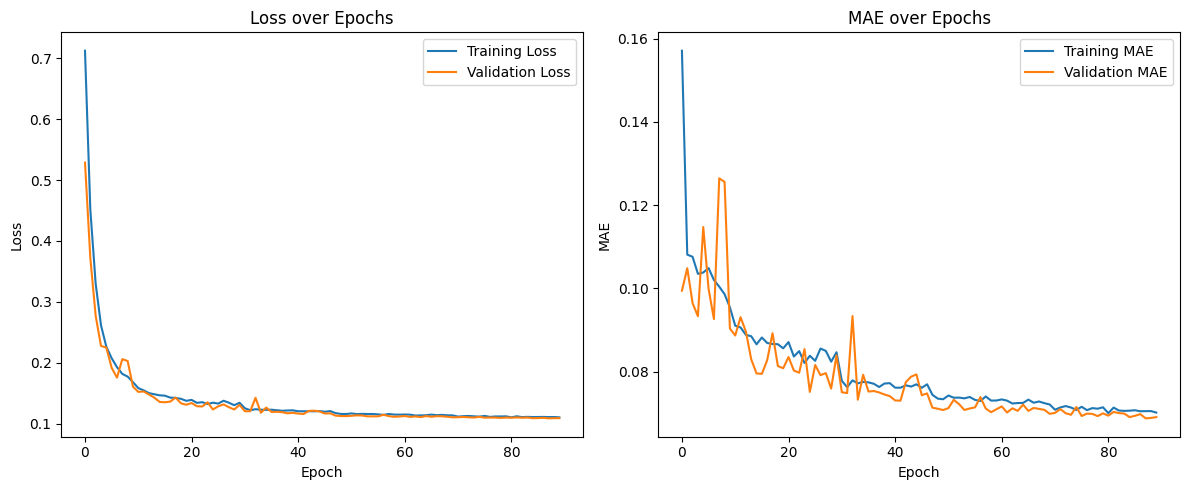

In [43]:
with open('training_history_m.pkl', 'rb') as f:
    history_data = pickle.load(f)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_data['loss'], label='Training Loss')
plt.plot(history_data['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss over Epochs')

plt.subplot(1, 2, 2)
plt.plot(history_data['custom_mae'], label='Training MAE')
plt.plot(history_data['val_custom_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.title('MAE over Epochs')

plt.tight_layout()
plt.show()


From these graphs, we observe a consistent reduction in loss over the course of training. Notably, there is no indication of overfitting, as both the training and validation loss follow a similar trajectory throughout the process. Even after running the training loop for 90 epochs, the loss continues to show a steady and gradual decrease with each epoch, suggesting that the model is still improving and learning without significant divergence between training and validation performance.

### Saving model and weights

In [44]:
model.save_weights('model_weights.weights.h5')
model.save('model.keras')

In [ ]:
import pandas as pd
history_df = pd.DataFrame(history.history)
history_df.to_csv('training_history_m.csv', index=False)
# just another way to save data


# Evaluation

The model must be evaluted by means of the following function, calling the test generator 50 times. The metrics adopted is the Rooted Mean Squared Error (RMSE).

To make a running example, we measure the performance of the statistical
baseline.

### Evaluation with the baseline

In [45]:
# Initialize lists to store the errors and the maximum errors
RMSE = []

# Generate and evaluate tot batches
tot = 50
for _ in range(tot):
    # Generate a batch
    batch_x, batch_y = next(test_gen)
    #uncomment the next line and call your model
    #predictions = model.predict(x_true, verbose=0)
    predictions = batch_x[...,3] #use the baseline as prediction

    # Denormalize data !!!
    predictions_denorm = predictions*x_train_std + x_train_mean
    true_values_denorm = batch_y[..., 0]*x_train_std + x_train_mean

    # Get the masks and calculate the errors
    diffMask = batch_y[..., 2]
    diff_errors_batch = np.where(diffMask, np.abs(predictions_denorm - true_values_denorm), np.nan)
    squared_errors = np.nanmean(diff_errors_batch**2,axis=(1,2))
    RMSE.append(np.sqrt(squared_errors))

RMSE = np.concatenate(RMSE)

print(f"RMSE :", np.mean(RMSE))
print(f"RMSE std :", np.std(RMSE))

RMSE : 0.6290978109630244
RMSE std : 0.18759007533052258


### Evaluation with the model

In [47]:
# Initialize lists to store the errors and the maximum errors
RMSE = []

# Generate and evaluate tot batches
tot = 50
for _ in range(tot):
    # Generate a batch
    batch_x, batch_y = next(test_gen)
    #uncomment the next line and call your model
    predictions = model.predict(batch_x, verbose=0)
    #predictions = batch_x[...,3] #use the baseline as prediction
    
    predictions = predictions[...,0]

    # Denormalize data !!!
    predictions_denorm = predictions*x_train_std + x_train_mean
    true_values_denorm = batch_y[..., 0]*x_train_std + x_train_mean

    # Get the masks and calculate the errors
    diffMask = batch_y[..., 2]
    diff_errors_batch = np.where(diffMask, np.abs(predictions_denorm - true_values_denorm), np.nan)
    squared_errors = np.nanmean(diff_errors_batch**2,axis=(1,2))
    RMSE.append(np.sqrt(squared_errors))

RMSE = np.concatenate(RMSE)

print(f"RMSE :", np.mean(RMSE))
print(f"RMSE std :", np.std(RMSE))

RMSE : 0.4684408097991529
RMSE std : 0.14071077320239805


### RMSE: 0.468

#### As we can see there is quite an improvement in terms of RMSE between the two approaches.
#### Also for the standard deviation

# Visualization of the predictions of the model

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
0.0 15.031028747558594
image 0; 0.0, 14.989999903520783
image 1; 0.0, 15.031028747558594


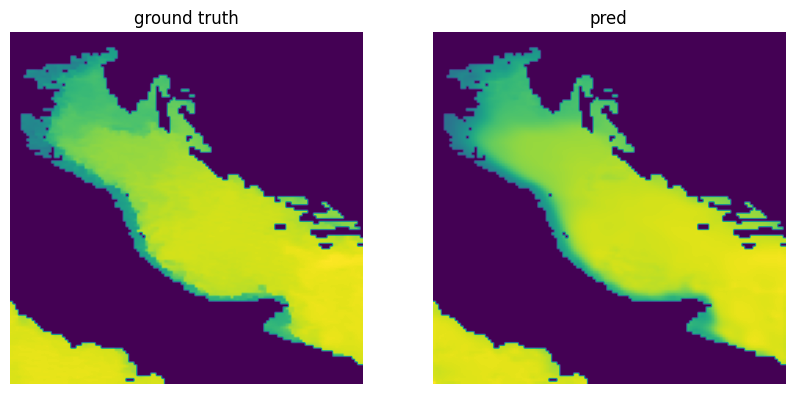

In [51]:
x,y = next(test_gen)
real_denorm = np.where(y[0,...,1],y[0,...,0]*x_train_std + x_train_mean,0.0)
pred = model.predict(x)
pred_denorm = np.where(y[0,...,1],pred[0,...,0]*x_train_std + x_train_mean,0.0)
plot_elements([real_denorm, pred_denorm,], ['ground truth', 'pred'])

From this perspective, we can observe that the model tends to smooth the areas of the map near the boundaries between different temperature regions. In contrast, the ground truth data presents sharper and more distinct transitions. While the model's prediction appears smoother overall, it still remains fairly accurate in general. 

This behavior is expected given the loss function used, which primarily focuses on minimizing the average errors in the masked areas. As a result, the model prioritizes reducing the loss in these regions, potentially at the expense of capturing finer details, such as sharp transitions at the boundaries between different temperature zones.